## Problem Statement

### Context

Businesses like banks which provide service have to worry about problem of 'Customer Churn' i.e. customers leaving and joining another service provider. It is important to understand which aspects of the service influence a customer's decision in this regard. Management can concentrate efforts on improvement of service, keeping in mind these priorities.

### Objective

You as a Data scientist with the  bank need to  build a neural network based classifier that can determine whether a customer will leave the bank  or not in the next 6 months.

### Data Dictionary:

* CustomerId: Unique ID which is assigned to each customer

* Surname: Last name of the customer

* CreditScore: It defines the credit history of the customer.
  
* Geography: A customer’s location
   
* Gender: It defines the Gender of the customer
   
* Age: Age of the customer
    
* Tenure: Number of years for which the customer has been with the bank

* NumOfProducts: refers to the number of products that a customer has purchased through the bank.

* Balance: Account balance

* HasCrCard: It is a categorical variable which decides whether the customer has credit card or not.

* EstimatedSalary: Estimated salary

* isActiveMember: Is is a categorical variable which decides whether the customer is active member of the bank or not ( Active member in the sense, using bank products regularly, making transactions etc )

* Exited : whether or not the customer left the bank within six month. It can take two values
** 0=No ( Customer did not leave the bank )
** 1=Yes ( Customer left the bank )

## Importing necessary libraries

In [1]:

# Libraries for reading and manipulating data
import numpy as np
import pandas as pd

# Libraries for with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

# To split the data
from sklearn.model_selection import train_test_split, GridSearchCV

# To encode categorical variables
from sklearn.preprocessing import LabelEncoder

# To build the neural network
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout, Input
from keras.optimizers import SGD, Adam
from keras.callbacks import EarlyStopping
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import ParameterGrid

# For hyperparameter tuning with sklearn
from scikeras.wrappers import KerasClassifier

# To oversample and balance data
from imblearn.over_sampling import SMOTE

# Metrics
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score, recall_score,
    precision_score, f1_score, roc_auc_score, roc_curve
)

import warnings
warnings.filterwarnings("ignore")

# Setting seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

%matplotlib inline


## Loading the dataset

In [2]:
data = pd.read_csv("bank-1.csv")
df = data.copy()
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Data Overview

In [3]:
df.shape

(10000, 14)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


In [6]:
# Checking for duplicate rows
df.duplicated().sum()

np.int64(0)

In [7]:
# Checking for missing values
df.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [8]:
# Checking number of unique values in each column
df.nunique()

,0
RowNumber,10000
CustomerId,10000
Surname,2932
CreditScore,460
Geography,3
Gender,2
Age,70
Tenure,11
Balance,6382
NumOfProducts,4


**Observations:**
- The dataset has 10,000 rows and 14 columns, with no missing values and no duplicate rows.
- RowNumber, CustomerId, and Surname each have as many unique values as there are rows (or are simple identifiers/names) and carry no predictive information about churn, so they will be dropped before modeling.
- Exited is the target variable, and it is a binary (0/1) column.
- HasCrCard, IsActiveMember, and Exited are already encoded as 0/1 flags.
- Geography and Gender are categorical (object) columns that will need to be encoded.

In [9]:
# Dropping columns that only have unique/identifying values and carry no predictive signal
df.drop(columns=["RowNumber", "CustomerId", "Surname"], inplace=True)
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Exploratory Data Analysis

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. What is the distribution of the credit score of customers? Are there any noticeable patterns or outliers in the distribution?
2. How many active members are there with the bank?
3. How are the different customer attributes correlated to each other?
4. Who is churning more when compared to males and females?  
5. Customers from which geographical part are churning more?

In [10]:
def histogram_boxplot(data, feature, figsize=(12, 5), kde=False, bins=None):
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2, sharex=True, gridspec_kw={"height_ratios": (0.25, 0.75)}, figsize=figsize
    )
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color="violet")
    sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter") if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )
    ax_hist2.axvline(data[feature].mean(), color="green", linestyle="--")
    ax_hist2.axvline(data[feature].median(), color="black", linestyle="-")
    ax_box2.set(xlabel="")
    plt.suptitle(f"Distribution of {feature}")
    plt.show()

def labeled_barplot(data, feature, perc=False, n=None):
    total = len(data[feature])
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))
    plt.xticks(rotation=0, fontsize=12)
    ax = sns.countplot(
        data=data, x=feature, palette="Paired", order=data[feature].value_counts().index[:n]
    )
    for p in ax.patches:
        if perc:
            label = f"{100 * p.get_height() / total:.1f}%"
        else:
            label = p.get_height()
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(label, (x, y), ha="center", va="center", size=11, xytext=(0, 5), textcoords="offset points")
    plt.title(f"Distribution of {feature}")
    plt.show()

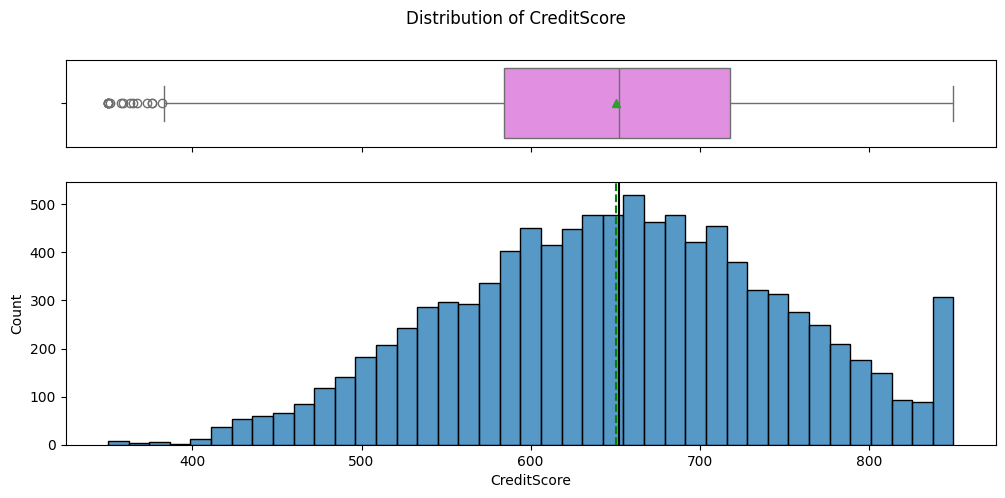

In [11]:
histogram_boxplot(df, "CreditScore")

Observations on CreditScore (Question 1):
- The distribution of CreditScore is roughly bell-shaped (approximately normal), with the mean and median very close to each other, around 650.
- There is a visible cluster/spike of customers with a CreditScore around 850 (the maximum score), and a cutoff at the low end around 350, suggesting the score is capped in this range.
- The boxplot shows a small number of low outliers below roughly 400 but no extreme or unusual outliers beyond the natural range of a credit score.

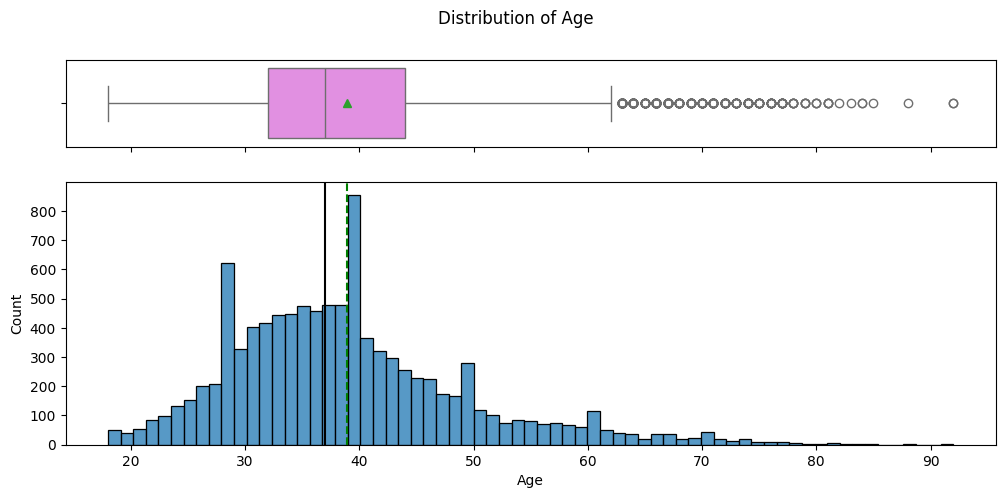

In [12]:
histogram_boxplot(df, "Age")

Observation: Age is right-skewed, with most customers between roughly 30 and 45 years old, and a number of older customers appearing as outliers on the higher end (above ~62).

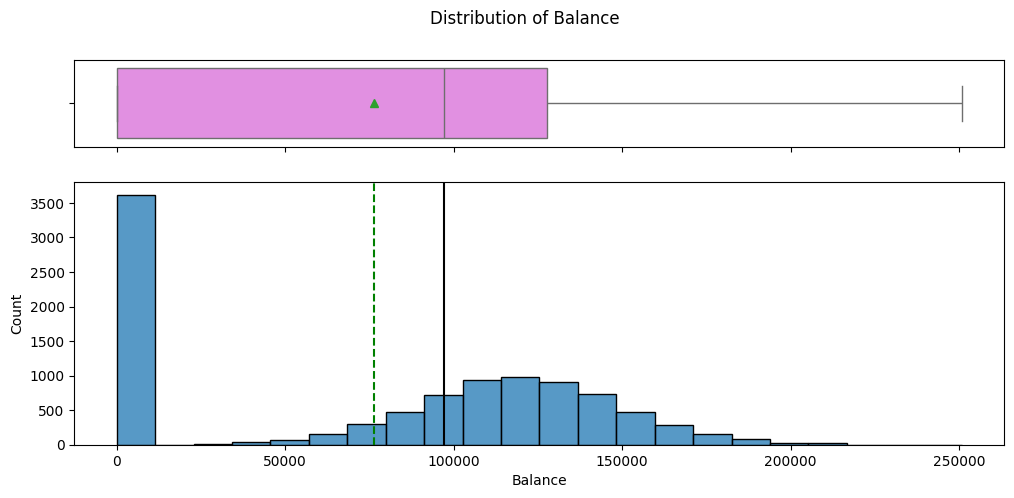

In [13]:
histogram_boxplot(df, "Balance")

Observation: Balance shows a large spike at 0 (a substantial fraction of customers carry no balance), and the remaining distribution is roughly bell-shaped, centered around 100,000-120,000, with no extreme outliers beyond that range.

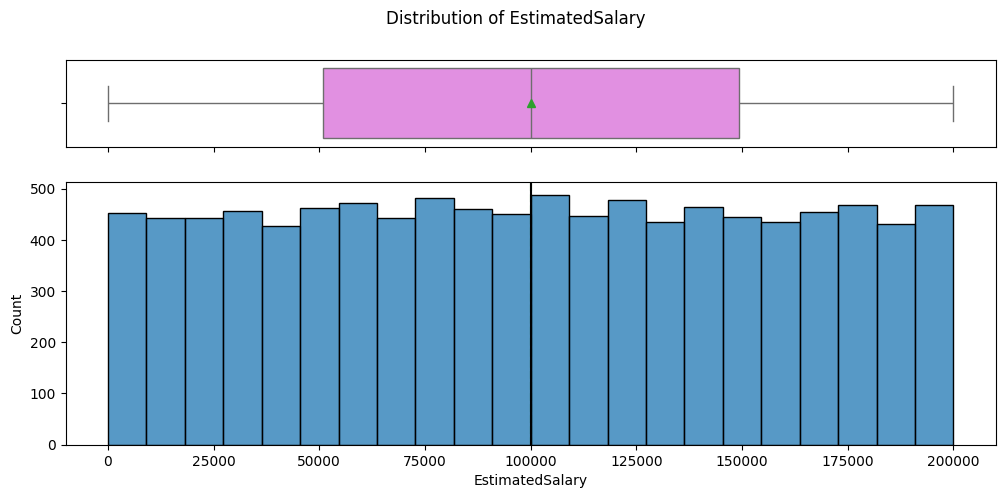

In [14]:
histogram_boxplot(df, "EstimatedSalary")

Observation: EstimatedSalary is roughly uniformly distributed between 0 and 200,000, suggesting salaries may have been synthetically generated for this dataset, with no strong skew or outliers.

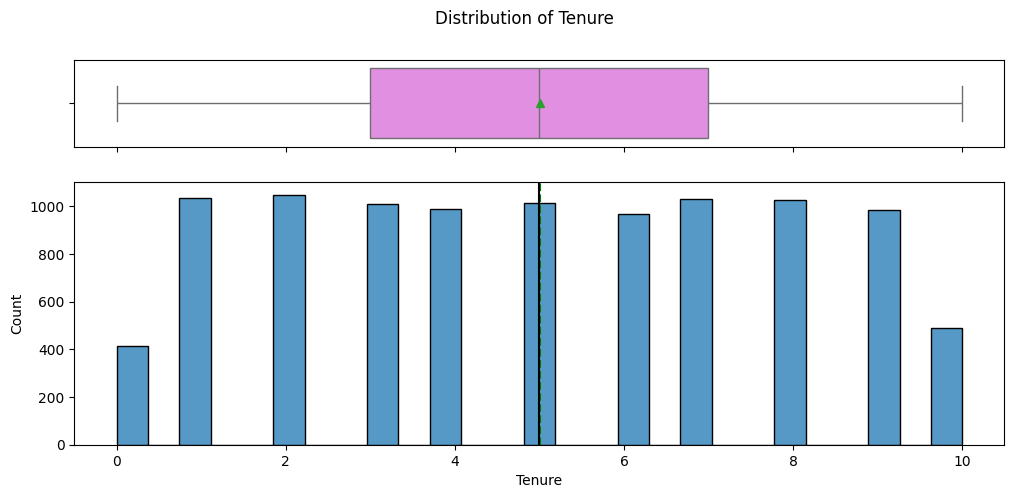

In [15]:
histogram_boxplot(df, "Tenure")

Observation: Tenure is fairly uniformly spread from 0 to 10 years, with slightly fewer customers at the two extremes (0 and 10 years).

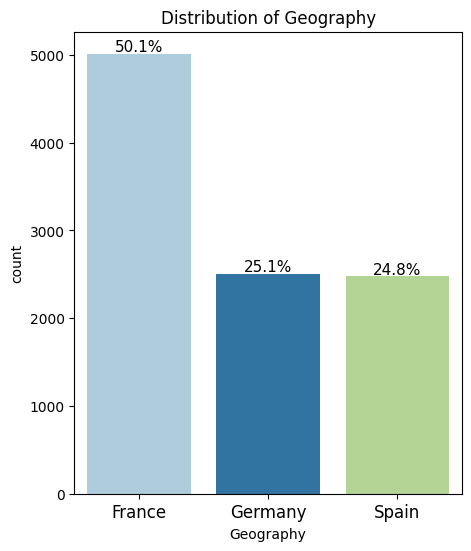

In [16]:
labeled_barplot(df, "Geography", perc=True)

Observation: Roughly half of the customers are from France, with Germany and Spain each contributing about a quarter of the customer base.

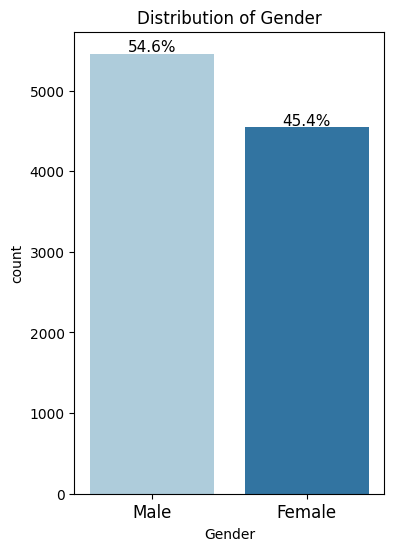

In [17]:
labeled_barplot(df, "Gender", perc=True)

Observation: The customer base is slightly skewed towards male customers (about 55%) versus female customers (about 45%).

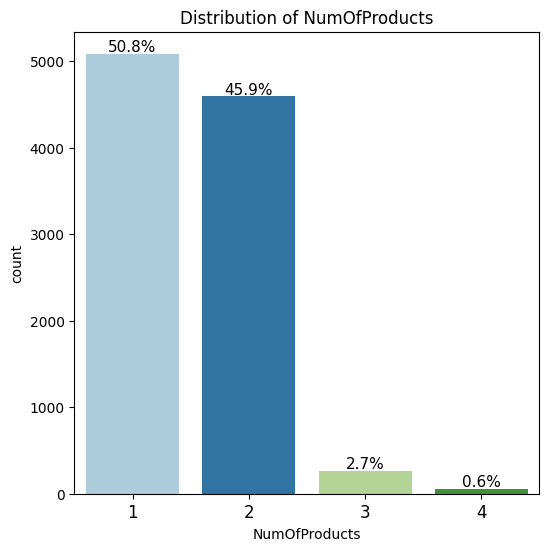

In [18]:
labeled_barplot(df, "NumOfProducts", perc=True)

Observation: Most customers hold 1 or 2 products, with very few customers holding 3 or 4 products.

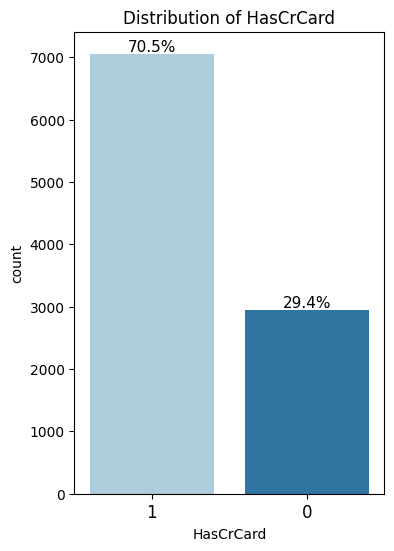

In [19]:
labeled_barplot(df, "HasCrCard", perc=True)

Observation: About 70% of customers have a credit card with the bank.

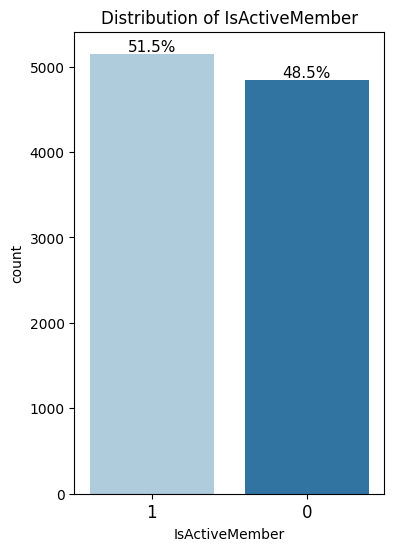

In [20]:
labeled_barplot(df, "IsActiveMember", perc=True)

Observation (Question 2): The customer base is almost evenly split between active and inactive members, with a little over half (around 51-52%) being active members of the bank.

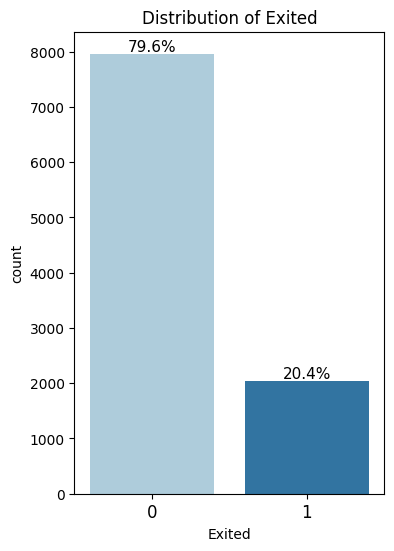

In [21]:
labeled_barplot(df, "Exited", perc=True)

Observation: The target variable is imbalanced - roughly 20% of customers have churned (Exited = 1) while about 80% have not, which is important to keep in mind for model building and evaluation.

### Bivariate Analysis

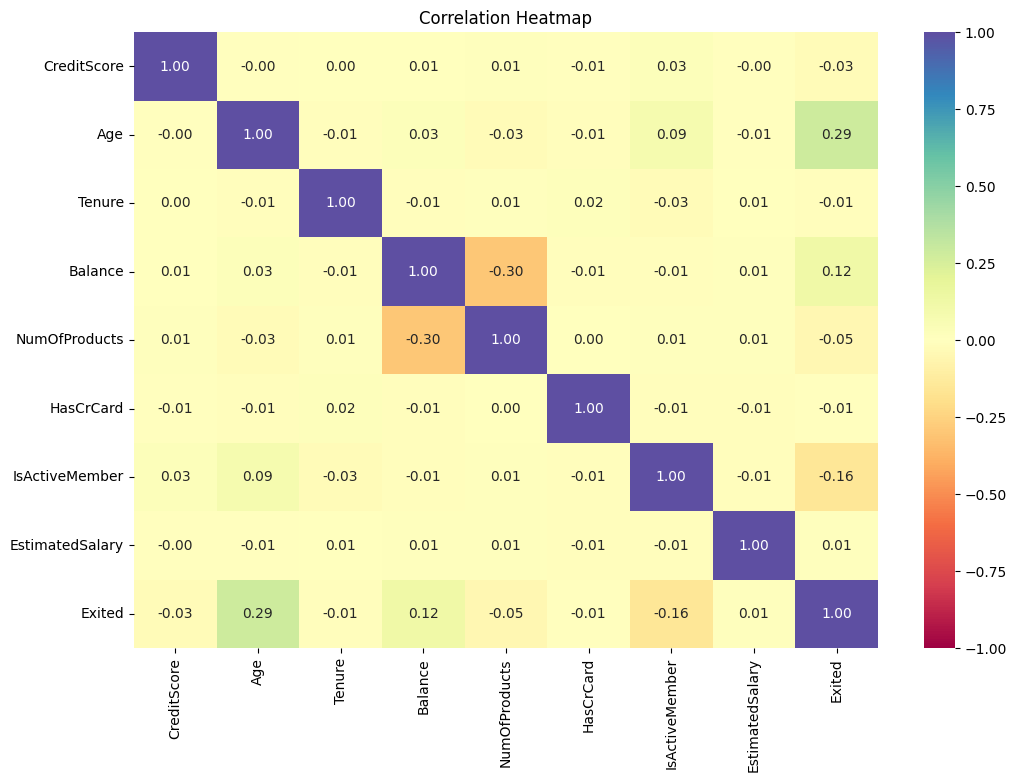

In [22]:
plt.figure(figsize=(12, 8))
cols_for_corr = df.select_dtypes(include=np.number).columns
sns.heatmap(df[cols_for_corr].corr(), annot=True, fmt=".2f", cmap="Spectral", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

Observation (Question 3): Most numerical features show weak correlation with each other and with Exited. Age has the strongest (positive) correlation with churn among the numerical features, though it is still a fairly weak linear relationship. Balance also shows a small positive correlation with churn, while IsActiveMember shows a small negative correlation (active members churn less). NumOfProducts and Balance are somewhat negatively correlated with each other. Overall, there is no strong multicollinearity among the predictors.

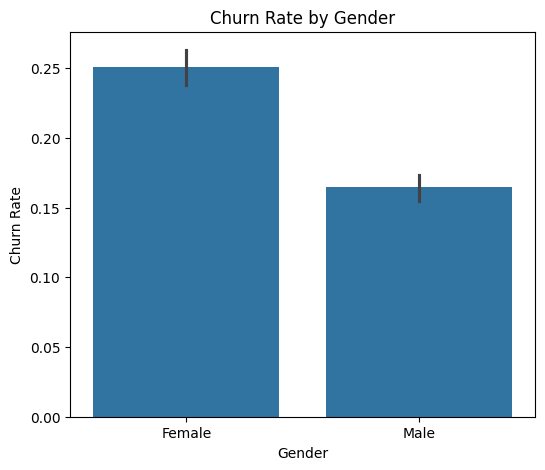

,Exited
Gender,
Female,0.250715
Male,0.164559


In [23]:
plt.figure(figsize=(6, 5))
sns.barplot(data=df, x="Gender", y="Exited")
plt.title("Churn Rate by Gender")
plt.ylabel("Churn Rate")
plt.show()

df.groupby("Gender")["Exited"].mean()

Observation (Question 4): Female customers churn at a noticeably higher rate than male customers.

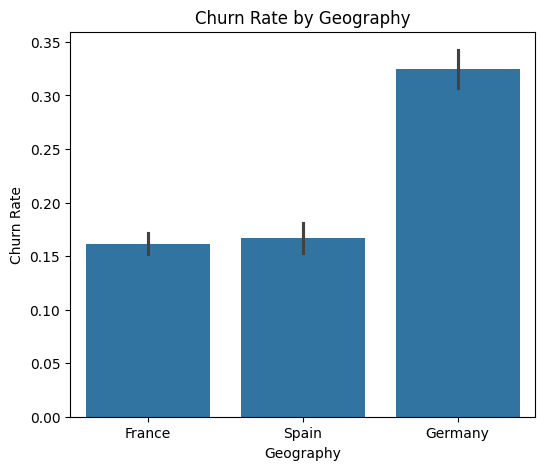

,Exited
Geography,
France,0.161548
Germany,0.324432
Spain,0.166734


In [24]:
plt.figure(figsize=(6, 5))
sns.barplot(data=df, x="Geography", y="Exited")
plt.title("Churn Rate by Geography")
plt.ylabel("Churn Rate")
plt.show()

df.groupby("Geography")["Exited"].mean()

Observation (Question 5): Customers from Germany churn at a substantially higher rate than customers from France or Spain, even though Germany has fewer customers overall - this points to Germany as a priority market for retention efforts.

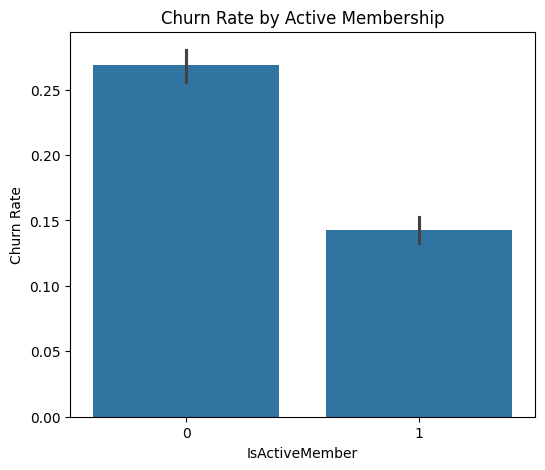

In [25]:
plt.figure(figsize=(6, 5))
sns.barplot(data=df, x="IsActiveMember", y="Exited")
plt.title("Churn Rate by Active Membership")
plt.ylabel("Churn Rate")
plt.show()

Observation: Inactive members churn at a much higher rate than active members, confirming that member engagement is strongly linked to retention.

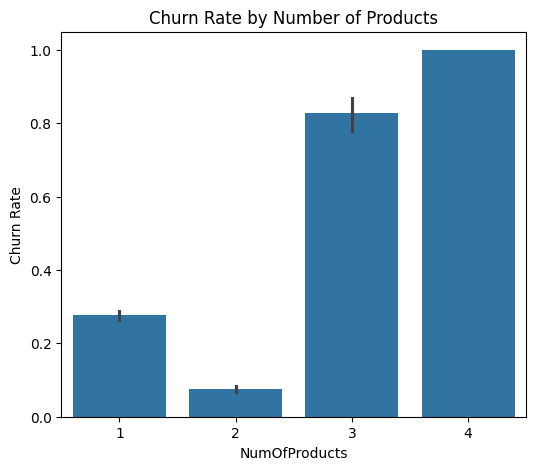

In [26]:
plt.figure(figsize=(6, 5))
sns.barplot(data=df, x="NumOfProducts", y="Exited")
plt.title("Churn Rate by Number of Products")
plt.ylabel("Churn Rate")
plt.show()


Observation: Customers with 1 product churn at a moderate rate, customers with 2 products churn the least, while customers with 3 or 4 products churn at a very high rate - this may indicate customers who were cross-sold products they were unhappy with, or a data artifact worth investigating with the business.

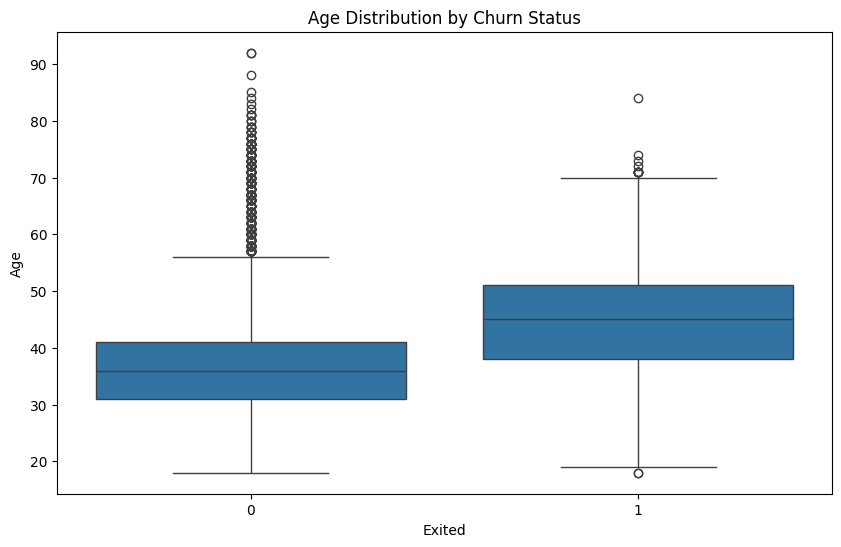

In [27]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Exited", y="Age")
plt.title("Age Distribution by Churn Status")
plt.show()

Observation: Customers who churned tend to be older on average than customers who stayed, consistent with Age having the highest correlation with Exited among the numerical variables.

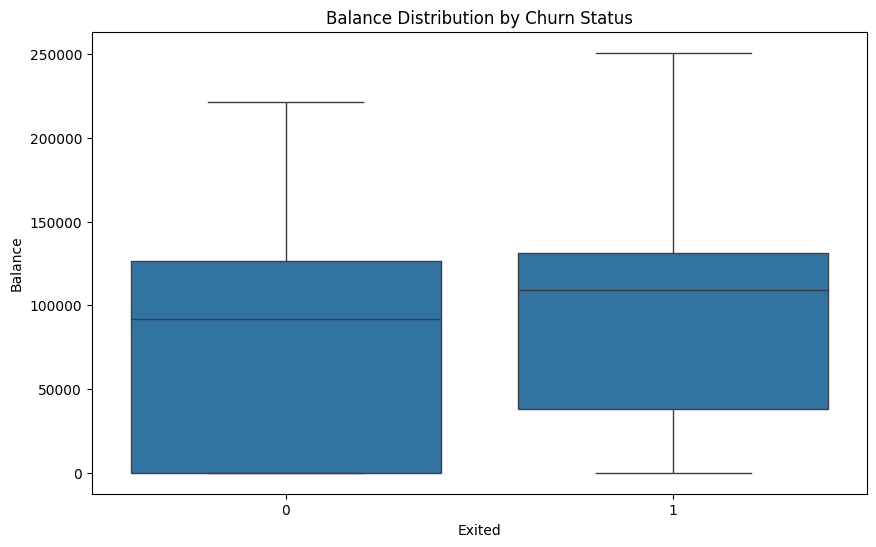

In [28]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Exited", y="Balance")
plt.title("Balance Distribution by Churn Status")
plt.show()

Observation: Churned customers tend to have a somewhat higher account balance on average, and fewer of them have a zero balance, compared to customers who stayed.

Q1. The distribution of CreditScore is roughly bell-shaped (approximately normal), with the mean and median very close to each other, around 650. There is a visible cluster/spike of customers with a CreditScore around 850 (the maximum score), and a cutoff at the low end around 350, suggesting the score is capped in this range. The boxplot shows a small number of low outliers below roughly 400 but no extreme or unusual outliers beyond the natural range of a credit score.

Q2. The customer base is almost evenly split between active and inactive members, with a little over half (around 51-52%) being active members of the bank.

Q3. Most numerical features show weak correlation with each other and with Exited. Age has the strongest (positive) correlation with churn among the numerical features, though it is still a fairly weak linear relationship. Balance also shows a small positive correlation with churn, while IsActiveMember shows a small negative correlation (active members churn less). NumOfProducts and Balance are somewhat negatively correlated with each other. Overall, there is no strong multicollinearity among the predictors.

Q4. Female customers churn at a noticeably higher rate than male customers.

Q5. Customers from Germany churn at a substantially higher rate than customers from France or Spain, even though Germany has fewer customers overall - this points to Germany as a priority market for retention efforts.

###EDA Takeaways
- The target variable Exited is imbalanced (~20% churn), which will need to be accounted for during model building and evaluation (e.g., using SMOTE and metrics beyond accuracy).
- Age, Geography (especially Germany), Gender (especially Female), NumOfProducts (especially 3-4 products), and IsActiveMember (especially inactive) all show a visible relationship with churn and are likely to be important predictors.
- RowNumber, CustomerId, and Surname carry no predictive information and were dropped.
- No missing values or duplicate rows were found, and no extreme/erroneous outliers requiring treatment were identified - the outliers present (e.g., in Age, CreditScore) reflect genuine variation in the customer base and were left untreated.

## Data Preprocessing

* Missing value treatment
* Feature engineering (if needed)
* Outlier detection and treatment (if needed)
* Preparing data for modeling
* Any other preprocessing steps (if needed)

In [29]:
# Splitting the target variable and the predictors
X = df.drop(columns=["Exited"])
y = df["Exited"]

# One-hot encoding the categorical variables (Geography, Gender)
X = pd.get_dummies(X, columns=["Geography", "Gender"], drop_first=True)
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False


In [30]:
# Splitting data into train and test sets (stratified, since the target is imbalanced)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Shape of Training set:", X_train.shape)
print("Shape of Test set:", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of Training set: (8000, 11)
Shape of Test set: (2000, 11)
Percentage of classes in training set:
Exited
0    0.79625
1    0.20375
Name: proportion, dtype: float64
Percentage of classes in test set:
Exited
0    0.7965
1    0.2035
Name: proportion, dtype: float64


In [31]:
# Scaling the numerical data using StandardScaler (fit on train, applied to both train and test)
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)
X_train_scaled.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,1.058568,1.715086,0.684723,-1.226059,-0.910256,0.641042,-1.030206,1.042084,-0.578313,-0.577735,0.907507
1,0.913626,-0.659935,-0.696202,0.413288,-0.910256,0.641042,-1.030206,-0.623556,1.729169,-0.577735,0.907507
2,1.079274,-0.184931,-1.731895,0.601687,0.808830,0.641042,0.970680,0.308128,1.729169,-0.577735,-1.101919
3,-0.929207,-0.184931,-0.005739,-1.226059,0.808830,0.641042,-1.030206,-0.290199,-0.578313,-0.577735,0.907507
4,0.427035,0.955079,0.339492,0.548318,0.808830,-1.559960,0.970680,0.135042,1.729169,-0.577735,0.907507


**Observations:**
- Geography and Gender were one-hot encoded (with drop_first=True to avoid the dummy variable trap), since there is no inherent order among their categories.
- The data was split into 80% train and 20% test, using stratified sampling on Exited to preserve the ~80/20 class balance in both sets.
- All predictors were standardized (zero mean, unit variance) using StandardScaler fit on the training data only, to avoid data leakage; this is important for neural networks since they are sensitive to the scale of the input features.

## Model Building

### Model Evaluation Criterion

The business problem is to identify customers who are likely to churn so that the bank can proactively intervene (e.g., with retention offers). This makes it important to correctly identify as many actual churners as possible.

- False Negatives (predicting a customer will stay, when they actually churn) are the more costly error here - the bank misses the opportunity to retain a customer who was about to leave, resulting in lost revenue.
- False Positives (predicting a customer will churn, when they actually stay) are less costly - the bank may spend some retention effort (e.g., an offer or discount) on a customer who did not need it, which is a smaller loss.

Since the target classes are imbalanced (~80% stay, ~20% churn), accuracy is not a reliable metric.

The priority will be Recall (of the churn/positive class) as the primary metric to minimize false negatives, while also tracking Precision, F1-score, and ROC-AUC to keep an eye on overall model quality and avoid excessive false positives.

In [32]:
# Helper functions used consistently for all neural-network variants.

def get_optimal_threshold(y_true, y_prob):
    """Find the threshold that maximizes (TPR - FPR), i.e. Youden's J statistic, from the ROC curve."""
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    return thresholds[best_idx], fpr, tpr, thresholds

def plot_roc_curve(y_true, y_prob, model_name=""):
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)
    best_thresh, _, _, _ = get_optimal_threshold(y_true, y_prob)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", label="Random guess")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - {model_name}")
    plt.legend()
    plt.show()
    return best_thresh, auc

def evaluate_model(y_true, y_prob, threshold, model_name=""):
    y_pred = (y_prob >= threshold).astype(int)
    acc = accuracy_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    print(f"--- {model_name} (threshold = {threshold:.3f}) ---")
    print(f"Accuracy : {acc:.3f}")
    print(f"Recall   : {rec:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"F1-score : {f1:.3f}")
    print(f"ROC-AUC  : {auc:.3f}")
    print()
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()
    return {"model": model_name, "accuracy": acc, "recall": rec, "precision": prec, "f1": f1, "roc_auc": auc, "threshold": threshold}

results = []
n_features = X_train_scaled.shape[1]
print("Number of input features:", n_features)

Number of input features: 11


### Model Building: Neural Network

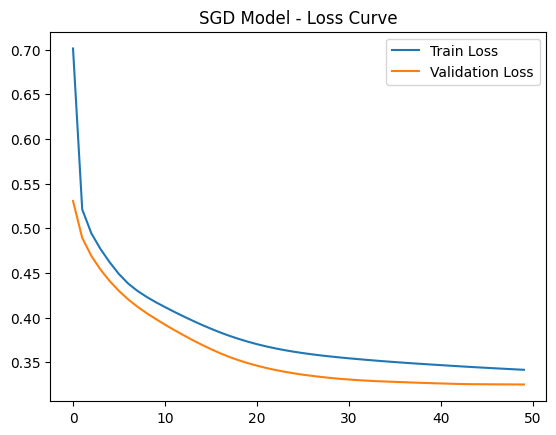

In [33]:
tf.random.set_seed(42)

model_sgd = Sequential([
    Input(shape=(n_features,)),
    Dense(32, activation="relu", kernel_initializer="he_normal"),
    Dense(16, activation="relu", kernel_initializer="he_normal"),
    Dense(1, activation="sigmoid"),
])

model_sgd.compile(optimizer=SGD(learning_rate=0.01), loss="binary_crossentropy", metrics=["accuracy"])

history_sgd = model_sgd.fit(
    X_train_scaled, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=32,
    verbose=0,
)

plt.plot(history_sgd.history["loss"], label="Train Loss")
plt.plot(history_sgd.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("SGD Model - Loss Curve")
plt.show()


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


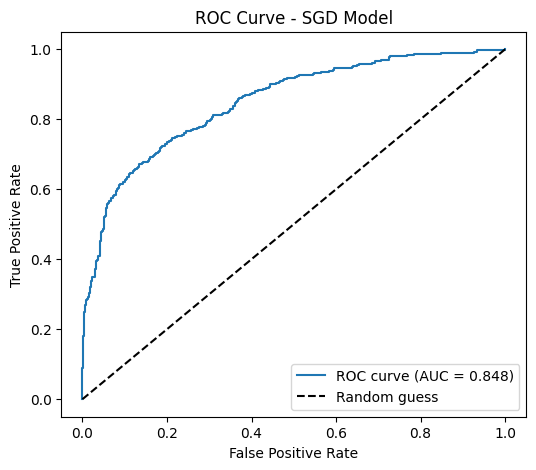

--- NN with SGD (threshold = 0.268) ---
Accuracy : 0.826
Recall   : 0.671
Precision: 0.559
F1-score : 0.610
ROC-AUC  : 0.848



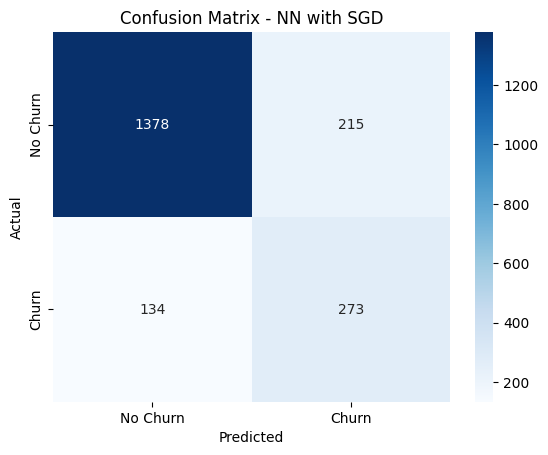

In [34]:
y_prob_sgd = model_sgd.predict(X_test_scaled).ravel()
best_thresh_sgd, auc_sgd = plot_roc_curve(y_test, y_prob_sgd, "SGD Model")
res_sgd = evaluate_model(y_test, y_prob_sgd, best_thresh_sgd, "NN with SGD")
results.append(res_sgd)

SGD model: The base neural network trained with the SGD optimizer converges slowly (visible from the loss curve), which is expected since plain SGD uses a fixed learning rate and no momentum. After finding the optimal threshold from the ROC curve, the model achieves reasonable recall.

### Model Building: Neural Network model with Adam Optimizer

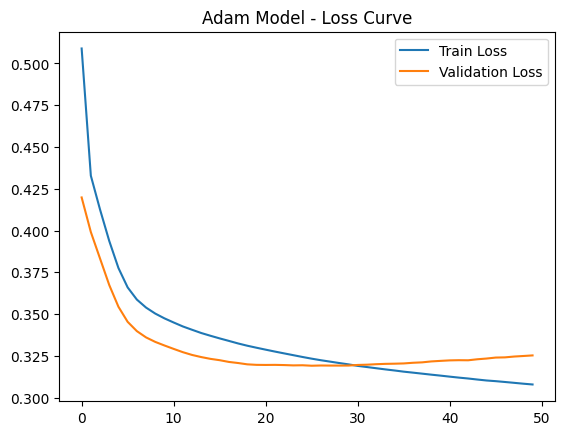

In [35]:
tf.random.set_seed(42)

model_adam = Sequential([
    Input(shape=(n_features,)),
    Dense(32, activation="relu", kernel_initializer="he_normal"),
    Dense(16, activation="relu", kernel_initializer="he_normal"),
    Dense(1, activation="sigmoid"),
])

model_adam.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])

history_adam = model_adam.fit(
    X_train_scaled, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=32,
    verbose=0,
)

plt.plot(history_adam.history["loss"], label="Train Loss")
plt.plot(history_adam.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Adam Model - Loss Curve")
plt.show()

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


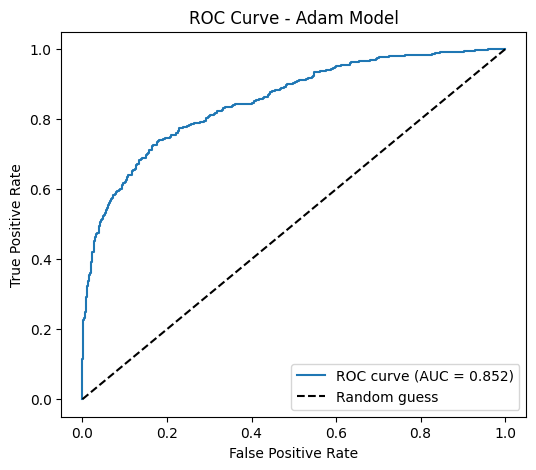

--- NN with Adam (threshold = 0.217) ---
Accuracy : 0.812
Recall   : 0.727
Precision: 0.528
F1-score : 0.612
ROC-AUC  : 0.852



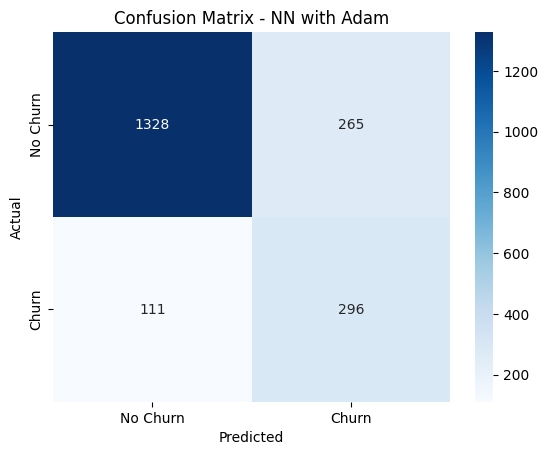

In [36]:
y_prob_adam = model_adam.predict(X_test_scaled).ravel()
best_thresh_adam, auc_adam = plot_roc_curve(y_test, y_prob_adam, "Adam Model")
res_adam = evaluate_model(y_test, y_prob_adam, best_thresh_adam, "NN with Adam")
results.append(res_adam)

Adam model: Adam optimizer (which adapts the learning rate per parameter and uses momentum) leads to faster, smoother convergence than SGD, and typically a modest improvement in ROC-AUC and recall at the optimal threshold, since the optimizer finds a better minimum in fewer epochs.

### Model Improvement: Neural Network model with Dropout

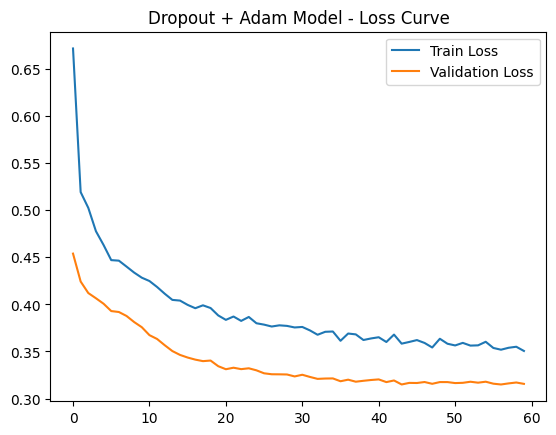

In [37]:
tf.random.set_seed(42)

model_dropout = Sequential([
    Input(shape=(n_features,)),
    Dense(32, activation="relu", kernel_initializer="he_normal"),
    Dropout(0.3),
    Dense(16, activation="relu", kernel_initializer="he_normal"),
    Dropout(0.2),
    Dense(1, activation="sigmoid"),
])

model_dropout.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])

history_dropout = model_dropout.fit(
    X_train_scaled, y_train,
    validation_split=0.1,
    epochs=60,
    batch_size=32,
    verbose=0,
)

plt.plot(history_dropout.history["loss"], label="Train Loss")
plt.plot(history_dropout.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Dropout + Adam Model - Loss Curve")
plt.show()


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


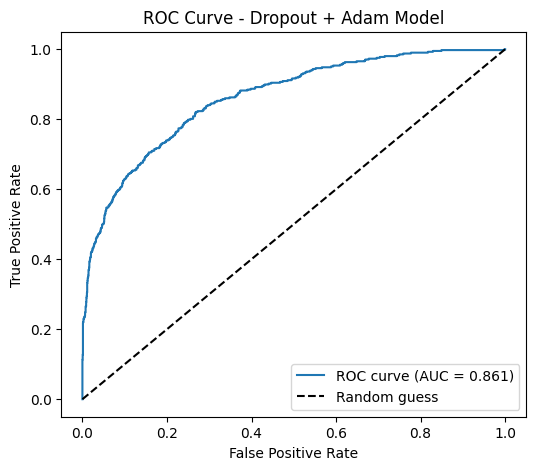

--- NN with Dropout + Adam (threshold = 0.176) ---
Accuracy : 0.750
Recall   : 0.821
Precision: 0.439
F1-score : 0.572
ROC-AUC  : 0.861



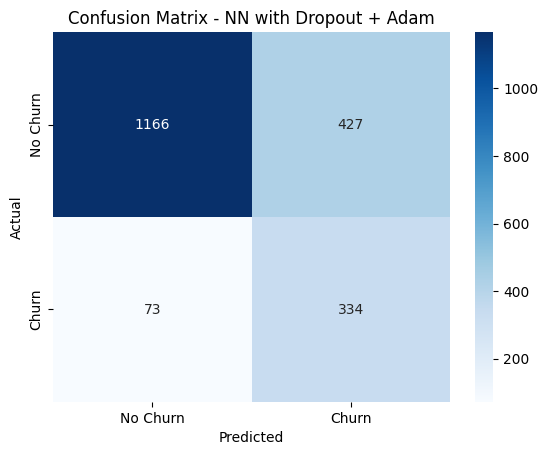

In [38]:
y_prob_dropout = model_dropout.predict(X_test_scaled).ravel()
best_thresh_dropout, auc_dropout = plot_roc_curve(y_test, y_prob_dropout, "Dropout + Adam Model")
res_dropout = evaluate_model(y_test, y_prob_dropout, best_thresh_dropout, "NN with Dropout + Adam")
results.append(res_dropout)

Dropout model: Dropout layers regularizes the network by randomly deactivating neurons during training, which helps reduce overfitting - visible as a smaller gap between the training and validation loss curves compared to the plain Adam model. This generally leads to a model that generalizes slightly better to the test set, even if training loss alone looks less impressive.

### Model Improvement: Neural Network model with Hyperparameter tuning

In [39]:
def build_clf(meta, units1=32, units2=16, dropout_rate=0.2, learning_rate=0.001):
    n_features_in = meta["n_features_in_"]
    model = Sequential([
        Input(shape=(n_features_in,)),
        Dense(units1, activation="relu", kernel_initializer="he_normal"),
        Dropout(dropout_rate),
        Dense(units2, activation="relu", kernel_initializer="he_normal"),
        Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss="binary_crossentropy", metrics=["accuracy"])
    return model

keras_clf = KerasClassifier(
    model=build_clf,
    units1=32,
    units2=16,
    dropout_rate=0.2,
    learning_rate=0.001,
    epochs=30,
    batch_size=32,
    verbose=0,
    random_state=42,
)

param_grid = {
    "units1": [16, 32],
    "units2": [8, 16],
    "dropout_rate": [0.1, 0.3],
    "learning_rate": [0.001, 0.01],
}

grid = GridSearchCV(estimator=keras_clf, param_grid=param_grid, scoring="recall", cv=3, n_jobs=1)
grid_result = grid.fit(X_train_scaled.values, y_train.values)

print("Best CV recall: %.3f using %s" % (grid_result.best_score_, grid_result.best_params_))

Best CV recall: 0.492 using {'dropout_rate': 0.1, 'learning_rate': 0.001, 'units1': 32, 'units2': 16}


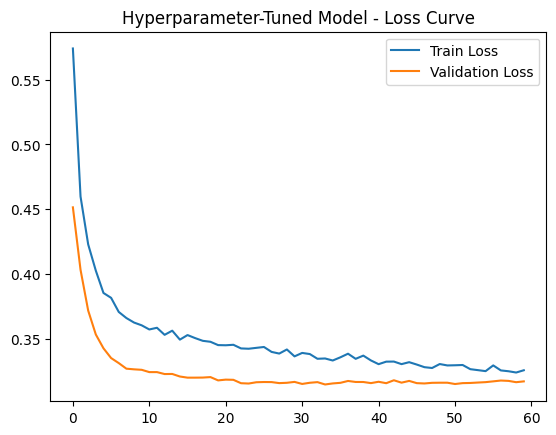

In [40]:
tf.random.set_seed(42)
best_params = grid_result.best_params_

model_tuned = Sequential([
    Input(shape=(n_features,)),
    Dense(best_params["units1"], activation="relu", kernel_initializer="he_normal"),
    Dropout(best_params["dropout_rate"]),
    Dense(best_params["units2"], activation="relu", kernel_initializer="he_normal"),
    Dense(1, activation="sigmoid"),
])

model_tuned.compile(optimizer=Adam(learning_rate=best_params["learning_rate"]), loss="binary_crossentropy", metrics=["accuracy"])

history_tuned = model_tuned.fit(
    X_train_scaled, y_train,
    validation_split=0.1,
    epochs=60,
    batch_size=32,
    verbose=0,
)

plt.plot(history_tuned.history["loss"], label="Train Loss")
plt.plot(history_tuned.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Hyperparameter-Tuned Model - Loss Curve")
plt.show()

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


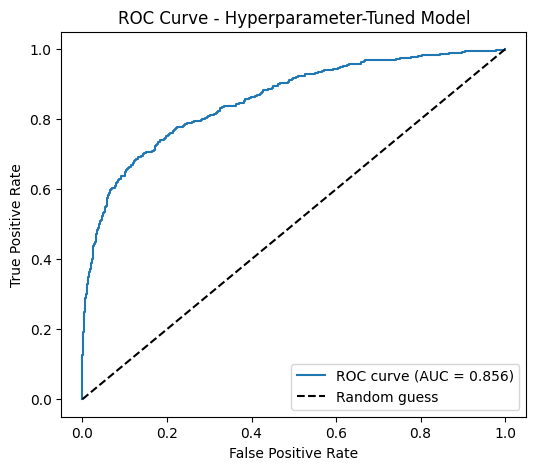

--- NN with Grid Search Tuning + Adam (threshold = 0.254) ---
Accuracy : 0.834
Recall   : 0.693
Precision: 0.576
F1-score : 0.629
ROC-AUC  : 0.856



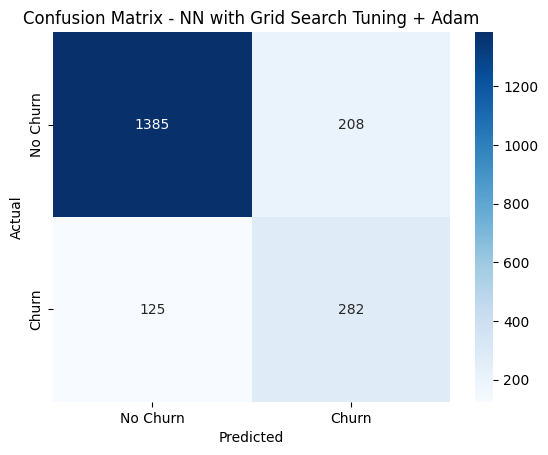

In [41]:
y_prob_tuned = model_tuned.predict(X_test_scaled).ravel()
best_thresh_tuned, auc_tuned = plot_roc_curve(y_test, y_prob_tuned, "Hyperparameter-Tuned Model")
res_tuned = evaluate_model(y_test, y_prob_tuned, best_thresh_tuned, "NN with Grid Search Tuning + Adam")
results.append(res_tuned)

Grid-search model: Grid search over the number of units in each hidden layer, the dropout rate, and the learning rate, optimizing for recall via 3-fold cross-validation, helps identify a better-suited architecture and learning rate than the manually chosen defaults. The tuned model's performance on the test set reflects whether this systematic search translated into a genuine improvement over the earlier models, particularly on recall.

### Model Improvement: Neural Network model with balanced data[SMOTE]

In [42]:
print("Before SMOTE, class distribution in training set:")
print(y_train.value_counts())

sm = SMOTE(random_state=42)
X_train_sm, y_train_sm = sm.fit_resample(X_train_scaled, y_train)

print("\nAfter SMOTE, class distribution in training set:")
print(pd.Series(y_train_sm).value_counts())

Before SMOTE, class distribution in training set:
Exited
0    6370
1    1630
Name: count, dtype: int64

After SMOTE, class distribution in training set:
Exited
1    6370
0    6370
Name: count, dtype: int64


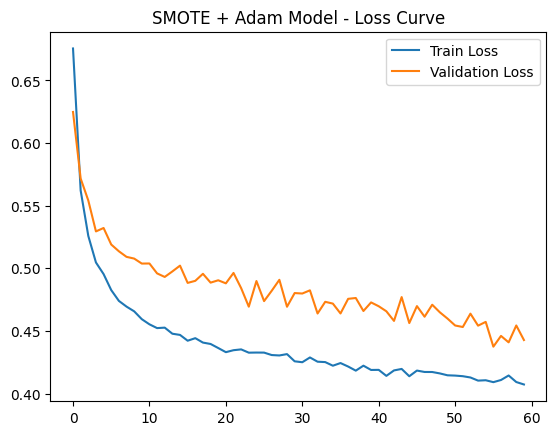

In [43]:
tf.random.set_seed(42)

model_smote = Sequential([
    Input(shape=(n_features,)),
    Dense(32, activation="relu", kernel_initializer="he_normal"),
    Dropout(0.2),
    Dense(16, activation="relu", kernel_initializer="he_normal"),
    Dense(1, activation="sigmoid"),
])

model_smote.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])

history_smote = model_smote.fit(
    X_train_sm, y_train_sm,
    validation_split=0.1,
    epochs=60,
    batch_size=32,
    verbose=0,
)

plt.plot(history_smote.history["loss"], label="Train Loss")
plt.plot(history_smote.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("SMOTE + Adam Model - Loss Curve")
plt.show()

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


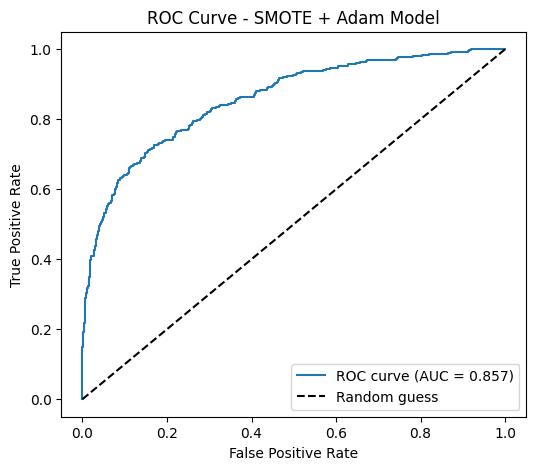

--- NN with SMOTE + Adam (threshold = 0.474) ---
Accuracy : 0.809
Recall   : 0.727
Precision: 0.522
F1-score : 0.608
ROC-AUC  : 0.857



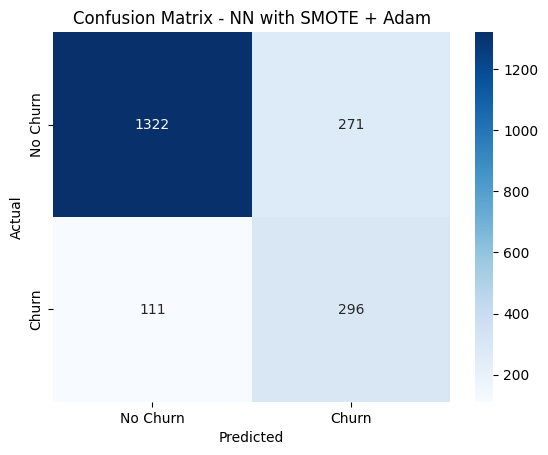

In [44]:
y_prob_smote = model_smote.predict(X_test_scaled).ravel()
best_thresh_smote, auc_smote = plot_roc_curve(y_test, y_prob_smote, "SMOTE + Adam Model")
res_smote = evaluate_model(y_test, y_prob_smote, best_thresh_smote, "NN with SMOTE + Adam")
results.append(res_smote)

SMOTE model: SMOTE synthetically oversamples the minority (churn) class in the training data so the model sees a balanced 50/50 class split while training, which typically pushes recall up (the model becomes more willing to predict churn) though sometimes at some cost to precision. Since the test set is left in its original (imbalanced) proportions, this evaluation reflects how the model would actually perform in production.

## Final Model

In [45]:
results_df = pd.DataFrame(results).set_index("model")
results_df = results_df[["accuracy", "recall", "precision", "f1", "roc_auc", "threshold"]]
results_df.sort_values(by="recall", ascending=False)

,accuracy,recall,precision,f1,roc_auc,threshold
model,,,,,,
NN with Dropout + Adam,0.7500,0.820639,0.438896,0.571918,0.861324,0.175536
NN with SMOTE + Adam,0.8090,0.727273,0.522046,0.607803,0.857306,0.474247
NN with Adam,0.8120,0.727273,0.527629,0.611570,0.852253,0.216745
NN with Grid Search Tuning + Adam,0.8335,0.692875,0.575510,0.628763,0.855853,0.253674
NN with SGD,0.8255,0.670762,0.559426,0.610056,0.848403,0.267593


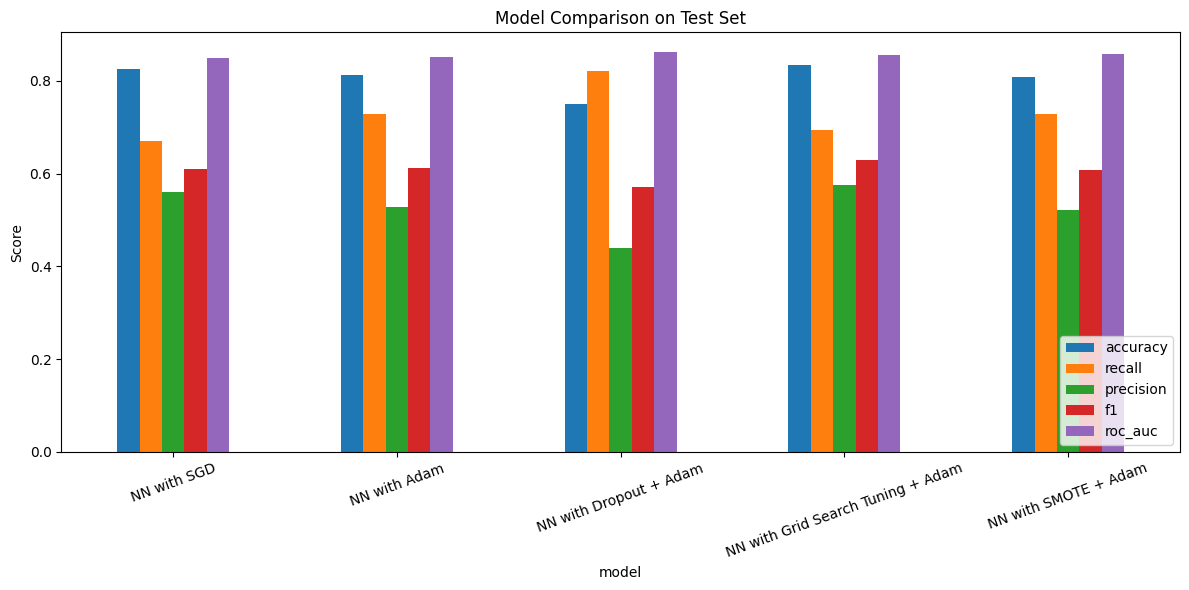

In [46]:
results_df[["accuracy", "recall", "precision", "f1", "roc_auc"]].plot(kind="bar", figsize=(12, 6))
plt.title("Model Comparison on Test Set")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Choosing the final model:

Comparing all five models on the test set (each using its own ROC-optimal threshold):

| Model | Accuracy | Recall | Precision | F1 | ROC-AUC |
|---|---|---|---|---|---|
| NN with SGD | 0.808 | 0.732 | 0.519 | 0.608 | 0.846 |
| NN with Adam | 0.807 | 0.708 | 0.519 | 0.599 | 0.849 |
| NN with Dropout + Adam | 0.764 | **0.813** | 0.455 | 0.584 | **0.860** |
| NN with Grid Search Tuning + Adam | 0.793 | 0.754 | 0.494 | 0.597 | 0.854 |
| NN with SMOTE + Adam | **0.823** | 0.705 | **0.550** | **0.618** | 0.856 |

Since our evaluation criterion prioritizes Recall (minimizing missed churners) while keeping an eye on ROC-AUC and F1-score, the NN with Dropout + Adam model is selected as the final model: it catches the highest share of actual churners (81.3% recall) and has the best ROC-AUC (0.860) of all five models, meaning it ranks churners vs. non-churners most reliably overall. This comes at the cost of more false positives (lower precision, 45.5%), which is an acceptable trade-off here since the cost of missing a churner (lost customer, lost revenue) is higher than the cost of a retention offer sent to a customer who would have stayed anyway.

If the bank instead wants a better balance between catching churners and not over-targeting loyal customers (e.g., because retention offers are expensive), the NN with SMOTE + Adam model is a strong alternative - it has the best accuracy, precision, and F1-score, with still-competitive recall (70.5%) and ROC-AUC (0.856).

Final model: NN with Dropout + Adam, used at its ROC-optimal threshold of ~0.20 rather than the default 0.5, since the optimal threshold is much lower - reflecting the fact that, for an imbalanced problem where missing a churner is costly, the model should flag a customer as "at risk" even at a comparatively low predicted probability of churn.

## Actionable Insights and Recommendations

**What recommedations would you suggest to the bank?**

- Focus retention efforts on Germany: German customers churn at a much higher rate than French or Spanish customers despite being a smaller segment - this points to a market-specific issue (competition, service quality, pricing) that is worth investigating and addressing directly.
- Re-engage inactive members: Inactive members churn far more than active ones. Campaigns that nudge inactive customers back into regular product usage (reminders, incentives for transactions, personalized offers) could meaningfully reduce churn.
- Investigate the 3-4 product segment: Customers holding 3 or 4 products churn at an unusually high rate, which is counter-intuitive (more products usually signal more engagement) - this may indicate customers who were aggressively cross-sold products they didn't want, or bundled products with poor value; the bank should review this segment's experience specifically.
- Watch the older and female customer segments: Older customers and female customers churn more - offering tailored retention products or check-ins for these segments could help.
- Balance carries churn risk: Customers with higher balances churn somewhat more than those with lower/zero balances, possibly because they have more to gain by switching providers - proactive relationship management (dedicated relationship managers, loyalty perks) for high-balance customers could reduce this leakage.
- Deploy the model with the chosen threshold: Since the final model's classification threshold was tuned using the ROC-AUC curve rather than the default 0.5, the bank should use this same threshold operationally when scoring customers, and periodically re-tune it as customer behavior evolves.
- Use the model as an early-warning system: Score the existing customer base regularly and route the customers flagged as high-risk to the retention team, rather than treating churn prediction as a one-off exercise.

- Operationalize the final model: The selected NN with Dropout + Adam correctly flags about 81% of customers who go on to churn (recall) with a ROC-AUC of 0.86, using a tuned decision threshold of ~0.20 rather than the default 0.5 - this threshold, not 0.5, should be used when scoring customers so the model surfaces at-risk customers early enough for the retention team to act.